# Consumer Spending — The Number You Acted On Is Not the Number in the Database

**Artifact class:** `tutorial`  ·  **Data mode:** `empirical`  ·  **Vintage:** FRED/ALFRED, pinned vintages

Every notebook so far has treated a published figure as fixed: retrieve it, check it, compute with
it. For national accounts data that assumption is false. **The same observation has a different
value depending on when you ask**, and a statistic retrieved today is not the statistic anyone saw
at the time.

Two mechanisms produce this, they are routinely confused, and they license completely different
conclusions:

**Rebasing.** A chained-dollar series is re-expressed in a new base year. Every level shifts by
close to the same factor; growth rates are essentially untouched. Comparing *levels* of a real
series across vintages is meaningless. Comparing growth rates is fine.

**Revision.** The underlying estimate actually changed as more source data arrived. Levels *and*
growth rates move, and the direction of a month's change can reverse.

Telling them apart takes one line — the ratio of the two vintages — and this notebook does that
before drawing any conclusion from either.

Real data only. No synthetic fallback. *Proprietary. SPDX-License-Identifier: LicenseRef-Proprietary*

## Learning Objectives

1. **Retrieve** a series as it stood on a past date (an ALFRED vintage) as well as currently, and
   explain why the two differ.
2. **Distinguish** rebasing from revision using the cross-vintage level ratio, and state which
   comparisons each one invalidates.
3. **Quantify** revision in the terms a decision-maker uses — not the level, but the growth rate,
   and whether its **sign** changed.
4. **Account** for publication lag: the data available on a date is shorter as well as different.
5. **Compare** revision magnitude across geographies and recognise that a figure's stability is
   itself unevenly distributed and unpublished.
6. **Choose** a defensible vintage policy for reproducible work, and record it.

## Prerequisites

**Knowledge.** D27 gentrification introduced `fetch_fred` and deflation. D02 introduced a publisher
that issues no uncertainty. This notebook is about a third situation: a publisher that issues a
number which later changes.

**Setup.** `FRED_API_KEY` in the environment or in the file `KRL_SECRETS_PATH` points at.

**Packages.** `pandas`, `numpy`, `matplotlib`, and `krl_tutorials_data`.

## Data Provenance

| Series | What | Role |
|---|---|---|
| `PCE` | Personal Consumption Expenditures, **nominal**, monthly, SAAR | revision, uncontaminated by rebasing |
| `PCEC96` | Real PCE, **chained dollars**, monthly, SAAR | rebasing, which looks like a huge revision |
| `{ST}PCE` | PCE by state, annual | how unevenly revision is distributed |

Each is retrieved twice: **as published on a pinned past date** and **as it stands now**. FRED's
underlying archive is ALFRED, and `fetch_fred(..., vintage=...)` requests the earlier publication.

**On the two series.** `PCE` is nominal, so it is never rebased; any cross-vintage difference in it
is genuine revision. `PCEC96` is in chained dollars and *is* rebased, so its cross-vintage
difference mixes both. Running the same comparison on both is what separates the mechanisms.

**SAAR.** Both national series are seasonally adjusted annual rates: a monthly figure expressed as
the annual total that month's pace implies. A month-over-month change in a SAAR series is a change
in pace, and is not an annual growth rate.

In [1]:
"""Configuration. Vintages are pinned constants, never 'the latest'."""
from __future__ import annotations

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_here = Path.cwd().resolve()
for _cand in (_here, *_here.parents):
    if (_cand / "src" / "krl_tutorials_data").is_dir():
        sys.path.insert(0, str(_cand / "src")); break
else:
    raise SystemExit("Could not locate krl_tutorials_data from " + str(_here))

from krl_tutorials_data.sources import fetch_fred, DataAccessError

# The window the two vintages have in common, and the historical publication
# date. Both pinned: an unpinned vintage would make every figure below change
# on re-run, which is the failure this notebook is about.
WINDOW_START, WINDOW_END = "2019-01-01", "2023-05-01"
PAST_VINTAGE = "2023-06-01"

NATIONAL = {
    "PCE": "Personal Consumption Expenditures, nominal, SAAR",
    "PCEC96": "Real Personal Consumption Expenditures, chained dollars, SAAR",
}

# Whether each series is expressed in CHAINED dollars. This is a property of the
# series definition, not something inferable from the numbers -- which is the
# point established in section 1. A nominal series is never rebased.
IS_CHAINED = {"PCE": False, "PCEC96": True}

STATE_WINDOW = ("2019-01-01", "2023-01-01")
STATE_POSTALS = (
    "AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO "
    "MT NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY"
).split()

pd.set_option("display.width", 150)
plt.rcParams["figure.dpi"] = 110

print(f"Common window   : {WINDOW_START} to {WINDOW_END}")
print(f"Past vintage    : {PAST_VINTAGE} (pinned)")
print(f"National series : {len(NATIONAL)}")
for _s, _d in NATIONAL.items():
    print(f"  {_s:<8} {_d}")
print(f"State series    : {len(STATE_POSTALS)} annual PCE series")
print("Chained (rebasable) :")
for _s, _c in IS_CHAINED.items():
    print(f"  {_s:<8} {_c}")

Common window   : 2019-01-01 to 2023-05-01
Past vintage    : 2023-06-01 (pinned)
National series : 2
  PCE      Personal Consumption Expenditures, nominal, SAAR
  PCEC96   Real Personal Consumption Expenditures, chained dollars, SAAR
State series    : 50 annual PCE series
Chained (rebasable) :
  PCE      False
  PCEC96   True


In [2]:
def both_vintages(series_id: str, start: str, end: str, freq: str = "m"):
    """The series as published on PAST_VINTAGE, and as it stands now."""
    past, prov_past = fetch_fred(
        series_id=series_id, start=start, end=end, frequency=freq,
        vintage=PAST_VINTAGE,
    )
    now, prov_now = fetch_fred(
        series_id=series_id, start=start, end=end, frequency=freq,
    )
    return past, now, prov_past, prov_now


try:
    frames, provenance = {}, {}
    for _sid in NATIONAL:
        _past, _now, _pp, _pn = both_vintages(_sid, WINDOW_START, WINDOW_END)
        frames[_sid] = (_past, _now)
        provenance[f"{_sid}_as_published"] = _pp
        provenance[f"{_sid}_current"] = _pn
except DataAccessError as exc:
    print("HALTED - real data could not be obtained.")
    print(f"  failure class : {type(exc).__name__}")
    print(f"  detail        : {exc}")
    print("\nNo synthetic fallback exists by design.")
    raise

print(f"Requested {WINDOW_START} to {WINDOW_END} at both vintages:")
for _sid, (_past, _now) in frames.items():
    _lag = len(_now) - len(_past)
    print(f"  {_sid:<8} as published {len(_past):>3} months | current {len(_now):>3} months "
          f"| {_lag} month(s) not yet published on {PAST_VINTAGE}")
print()
print("Publication lag is the first difference and the easiest to forget: the data")
print("available on a date is SHORTER as well as different. An analysis run then could")
print("not have seen the final month, whatever its value has since become.")

Requested 2019-01-01 to 2023-05-01 at both vintages:
  PCE      as published  52 months | current  53 months | 1 month(s) not yet published on 2023-06-01
  PCEC96   as published  52 months | current  53 months | 1 month(s) not yet published on 2023-06-01

Publication lag is the first difference and the easiest to forget: the data
available on a date is SHORTER as well as different. An analysis run then could
not have seen the final month, whatever its value has since become.


## 1. Rebasing or revision — and why the data alone cannot tell you

The tempting test: if a series was re-expressed in a new base year, every observation is multiplied
by close to the same factor, so the ratio `current / as-published` should be near-constant. If the
estimates were genuinely revised, the ratio should vary. Threshold the variability and you have a
classifier.

**That test does not work, and it is worth seeing it fail.** Both series are run through it below.

The reason it fails is that the ratio decomposes into two parts — a **shift** (its central value)
and a **variation about that shift** — and only the shift distinguishes rebasing. The variation is
revision, and it is a similar size in both series. A test that looks only at variability is reading
the component that carries no information about the question.

What actually settles it is knowing whether the series is expressed in **chained dollars**. A
nominal series cannot be rebased; there is no base year to change. That is a fact about the series
definition, declared in the configuration above, and it is not recoverable from the observations.

In [3]:
diagnosis = {}
for sid, (past, now) in frames.items():
    merged = past.merge(now, on="date", suffixes=("_past", "_now")).dropna()
    merged["ratio"] = merged.value_now / merged.value_past
    shift = float(merged.ratio.median())
    # Variation about the shift is the part that is revision in either series.
    merged["residual_pct"] = (merged.ratio / shift - 1) * 100
    diagnosis[sid] = {
        "merged": merged,
        "shift_pct": (shift - 1) * 100,
        "sd": float(merged.ratio.std()),
        "residual_sd_pct": float(merged.residual_pct.std()),
        "chained": IS_CHAINED[sid],
    }

print(f"{'series':<9}{'shift %':>10}{'ratio sd':>11}{'residual sd %':>15}{'chained':>10}")
for sid, d in diagnosis.items():
    print(f"{sid:<9}{d['shift_pct']:>+10.3f}{d['sd']:>11.6f}"
          f"{d['residual_sd_pct']:>15.3f}{str(d['chained']):>10}")
print()

_sds = [d["sd"] for d in diagnosis.values()]
print(f"The variability test fails: the two ratio standard deviations are "
      f"{_sds[0]:.6f} and {_sds[1]:.6f},")
print("which do not separate the series at any threshold. Their RESIDUAL variation - the")
print("revision component - is likewise similar. What differs is the SHIFT:")
for sid, d in diagnosis.items():
    print(f"  {sid:<8} shift {d['shift_pct']:+.3f}%")
print()
for sid, d in diagnosis.items():
    if d["chained"]:
        print(f"{sid} is chained, so its {d['shift_pct']:+.2f}% shift is a change of base year")
        print("  plus revision, and its LEVELS may not be compared across vintages.")
    else:
        print(f"{sid} is nominal and cannot be rebased, so its {d['shift_pct']:+.2f}% shift is")
        print("  revision throughout.")
print()
print("The classification came from the series definition, not from the numbers. A")
print("data-only diagnostic would have labelled both the same way and been wrong once.")

series      shift %   ratio sd  residual sd %   chained
PCE          +1.304   0.007199          0.711     False
PCEC96       +7.539   0.006083          0.566      True

The variability test fails: the two ratio standard deviations are 0.007199 and 0.006083,
which do not separate the series at any threshold. Their RESIDUAL variation - the
revision component - is likewise similar. What differs is the SHIFT:
  PCE      shift +1.304%
  PCEC96   shift +7.539%

PCE is nominal and cannot be rebased, so its +1.30% shift is
  revision throughout.
PCEC96 is chained, so its +7.54% shift is a change of base year
  plus revision, and its LEVELS may not be compared across vintages.

The classification came from the series definition, not from the numbers. A
data-only diagnostic would have labelled both the same way and been wrong once.


## 2. What actually changed: growth, and its sign

Levels are not what anyone acts on. The reported quantity is the **change** — whether spending rose
or fell, and by how much. Growth rates survive rebasing, so they are the right place to look for
revision in either series.

In [4]:
growth = {}
for sid, d in diagnosis.items():
    g = d["merged"].sort_values("date").copy()
    g["growth_past"] = g.value_past.pct_change() * 100
    g["growth_now"] = g.value_now.pct_change() * 100
    g = g.dropna(subset=["growth_past", "growth_now"])
    g["delta_pp"] = g.growth_now - g.growth_past
    g["sign_flip"] = (g.growth_past > 0) != (g.growth_now > 0)
    growth[sid] = g

    _kind = "chained" if d["chained"] else "nominal"
    print(f"{sid} ({_kind}) -- month-over-month growth, {len(g)} months")
    print(f"  mean |revision to growth| : {g.delta_pp.abs().mean():.4f} pp")
    print(f"  largest                   : {g.delta_pp.abs().max():.4f} pp "
          f"({g.loc[g.delta_pp.abs().idxmax(), 'date'].strftime('%Y-%m')})")
    print(f"  correlation across vintages: "
          f"{np.corrcoef(g.growth_past, g.growth_now)[0, 1]:.4f}")
    print(f"  months whose growth SIGN reversed: {int(g.sign_flip.sum())} of {len(g)}")
    if int(g.sign_flip.sum()):
        for _, r in g.loc[g.sign_flip].iterrows():
            print(f"    {r.date.strftime('%Y-%m')}: as published "
                  f"{r.growth_past:+.3f}% -> now {r.growth_now:+.3f}%")
    print()

print("A sign reversal is the consequential case. For those months the published series")
print("said spending moved one way and the current series says it moved the other, so an")
print("analysis run then reached the opposite conclusion from one run today - using the")
print("same source, the same series and the same month.")

PCE (nominal) -- month-over-month growth, 51 months
  mean |revision to growth| : 0.2418 pp
  largest                   : 1.1645 pp (2020-04)
  correlation across vintages: 0.9933
  months whose growth SIGN reversed: 3 of 51
    2020-02: as published +0.386% -> now -0.270%
    2021-12: as published -0.214% -> now +0.245%
    2022-07: as published -0.098% -> now +0.084%

PCEC96 (chained) -- month-over-month growth, 51 months
  mean |revision to growth| : 0.2295 pp
  largest                   : 1.0653 pp (2020-04)
  correlation across vintages: 0.9932
  months whose growth SIGN reversed: 7 of 51
    2019-04: as published -0.035% -> now +0.008%
    2020-02: as published +0.276% -> now -0.346%
    2020-12: as published -0.359% -> now +0.404%
    2021-11: as published -0.103% -> now +0.202%
    2022-05: as published +0.068% -> now -0.140%
    2022-07: as published -0.004% -> now +0.089%
    2023-03: as published -0.022% -> now +0.014%

A sign reversal is the consequential case. For those mo

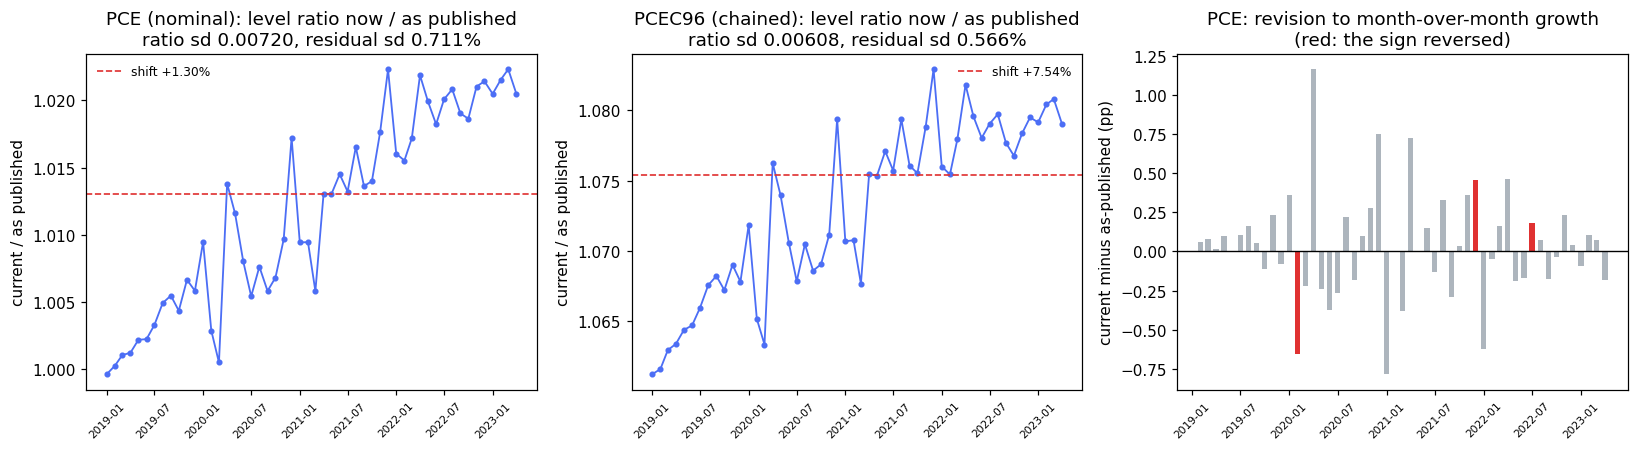

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

for ax, (sid, d) in zip(axes[:2], diagnosis.items()):
    merged = d["merged"]
    ax.plot(merged.date, merged.ratio, "o-", ms=3, lw=1.2, color="#4c6ef5")
    ax.axhline(merged.ratio.median(), color="#e03131", ls="--", lw=1.1,
               label=f"shift {d['shift_pct']:+.2f}%")
    _kind = "chained" if d["chained"] else "nominal"
    ax.set_title(f"{sid} ({_kind}): level ratio now / as published\n"
                 f"ratio sd {d['sd']:.5f}, residual sd {d['residual_sd_pct']:.3f}%")
    ax.set_ylabel("current / as published")
    ax.tick_params(axis="x", rotation=45, labelsize=7)
    ax.legend(frameon=False, fontsize=8)

g = growth["PCE"]
axes[2].bar(g.date, g.delta_pp, width=20,
            color=np.where(g.sign_flip, "#e03131", "#adb5bd"))
axes[2].axhline(0, color="k", lw=.9)
axes[2].set_title("PCE: revision to month-over-month growth\n(red: the sign reversed)")
axes[2].set_ylabel("current minus as-published (pp)")
axes[2].tick_params(axis="x", rotation=45, labelsize=7)
plt.tight_layout(); plt.show()

## 3. Revision is not evenly distributed

A national figure is one number; the state figures underneath it are revised by different amounts.
That matters because a state's estimate being *more revisable* is a form of uncertainty — and it is
not published anywhere as one.

In [6]:
rows, failures = [], []
for postal in STATE_POSTALS:
    sid = f"{postal}PCE"
    try:
        past, _p = fetch_fred(series_id=sid, start=STATE_WINDOW[0],
                              end=STATE_WINDOW[1], frequency="a",
                              vintage=PAST_VINTAGE)
        now, _n = fetch_fred(series_id=sid, start=STATE_WINDOW[0],
                             end=STATE_WINDOW[1], frequency="a")
    except DataAccessError as exc:
        failures.append((postal, type(exc).__name__))
        continue
    m = past.merge(now, on="date", suffixes=("_past", "_now")).dropna()
    if m.empty:
        failures.append((postal, "no overlapping years"))
        continue
    rows.append({
        "state": postal,
        "years": len(m),
        "median_level_revision_pct": float(((m.value_now / m.value_past - 1) * 100).median()),
        "max_level_revision_pct": float(((m.value_now / m.value_past - 1) * 100).abs().max()),
    })

states = pd.DataFrame(rows).sort_values("median_level_revision_pct")
print(f"States compared : {len(states)}   (failed: {len(failures)})")
if failures:
    print(f"  not retrieved : {failures[:6]}")
print()
print(f"Median level revision between the {PAST_VINTAGE} vintage and today:")
print(f"  across states : min {states.median_level_revision_pct.min():+.3f}%  "
      f"median {states.median_level_revision_pct.median():+.3f}%  "
      f"max {states.median_level_revision_pct.max():+.3f}%")
print(f"  spread        : {states.median_level_revision_pct.max() - states.median_level_revision_pct.min():.3f} "
      f"percentage points between the least and most revised state")
print()
print("Least revised:")
for _, r in states.head(4).iterrows():
    print(f"  {r.state}  {r.median_level_revision_pct:+.3f}%")
print("Most revised:")
for _, r in states.tail(4).iterrows():
    print(f"  {r.state}  {r.median_level_revision_pct:+.3f}%")

States compared : 50   (failed: 0)

Median level revision between the 2023-06-01 vintage and today:
  across states : min -2.621%  median +0.373%  max +4.103%
  spread        : 6.724 percentage points between the least and most revised state

Least revised:
  SD  -2.621%
  AK  -2.014%
  ID  -1.248%
  NE  -0.845%
Most revised:
  ME  +2.786%
  ND  +2.935%
  WY  +3.237%
  RI  +4.103%


## Limitations

- **One vintage pair.** Everything here compares a single past publication date with today. The
  full revision path runs through hundreds of intermediate vintages, and the largest revision for a
  given month may sit at neither endpoint.
- **The rebasing test is a diagnostic, not a proof.** A near-constant ratio is consistent with
  rebasing; it would also arise from any uniform multiplicative correction. The threshold is a
  declared convention, not a property of the data.
- **Growth is computed month over month on a SAAR series.** That is a change in annualised pace, not
  a monthly or an annual growth rate, and it is not comparable to a year-over-year figure.
- **Sign reversals are counted on the point estimates.** Neither vintage publishes an interval, so
  nothing here says whether either month's change was distinguishable from zero to begin with — a
  reversal between two indistinguishable numbers is less remarkable than one between two firm ones.
- **State PCE is annual and thinly covered** in this window, so the state comparison rests on few
  years per state and is reported as a spread, not a ranking to act on.
- **No causal claim.** Nothing here explains why any figure was revised; the source-data and
  methodology changes behind each revision are documented by BEA and are not reproduced.

In [7]:
"""Findings. Every number below is rendered from a value computed above."""
pce, real = diagnosis["PCE"], diagnosis["PCEC96"]
gp, gr = growth["PCE"], growth["PCEC96"]

print("FINDINGS")
print("=" * 78)
print(f"1. The variability test for rebasing DOES NOT WORK. Ratio sd is "
      f"{pce['sd']:.6f} for nominal PCE")
print(f"   and {real['sd']:.6f} for real PCE - no threshold separates them, and the")
print(f"   residual variation is similar too ({pce['residual_sd_pct']:.3f}% vs "
      f"{real['residual_sd_pct']:.3f}%).")
print(f"2. What differs is the SHIFT: {pce['shift_pct']:+.2f}% for nominal PCE against "
      f"{real['shift_pct']:+.2f}% for real PCE.")
print(f"   Real PCE is chained, so most of its shift is a change of base year and its LEVELS")
print(f"   may not be compared across vintages. Nominal PCE cannot be rebased, so its shift")
print(f"   is revision. That classification comes from the series definition, not the data.")
print(f"3. Growth rates survive rebasing. Cross-vintage correlation of month-over-month")
print(f"   growth: {np.corrcoef(gr.growth_past, gr.growth_now)[0, 1]:.4f} (real), "
      f"{np.corrcoef(gp.growth_past, gp.growth_now)[0, 1]:.4f} (nominal).")
print(f"   Mean absolute revision to growth: {gr.delta_pp.abs().mean():.3f} pp (real), "
      f"{gp.delta_pp.abs().mean():.3f} pp (nominal).")
print(f"4. {int(gp.sign_flip.sum())} of {len(gp)} months had the SIGN of nominal PCE growth reverse "
      f"between vintages,")
print(f"   and {int(gr.sign_flip.sum())} of {len(gr)} for real PCE. For those months the two "
      f"vintages support opposite")
print(f"   conclusions about whether spending rose or fell.")
print(f"5. Publication lag: on {PAST_VINTAGE} the nominal series ran "
      f"{len(frames['PCE'][1]) - len(frames['PCE'][0])} month(s) shorter than it")
print(f"   does now. The data available at a date is shorter as well as different.")
print(f"6. Across {len(states)} states, the median level revision ranges from "
      f"{states.median_level_revision_pct.min():+.2f}% to "
      f"{states.median_level_revision_pct.max():+.2f}%")
print(f"   - a {states.median_level_revision_pct.max() - states.median_level_revision_pct.min():.2f} "
      f"pp spread. How revisable a state's figure is, is itself unpublished.")
print("=" * 78)

FINDINGS
1. The variability test for rebasing DOES NOT WORK. Ratio sd is 0.007199 for nominal PCE
   and 0.006083 for real PCE - no threshold separates them, and the
   residual variation is similar too (0.711% vs 0.566%).
2. What differs is the SHIFT: +1.30% for nominal PCE against +7.54% for real PCE.
   Real PCE is chained, so most of its shift is a change of base year and its LEVELS
   may not be compared across vintages. Nominal PCE cannot be rebased, so its shift
   is revision. That classification comes from the series definition, not the data.
3. Growth rates survive rebasing. Cross-vintage correlation of month-over-month
   growth: 0.9932 (real), 0.9933 (nominal).
   Mean absolute revision to growth: 0.229 pp (real), 0.242 pp (nominal).
4. 3 of 51 months had the SIGN of nominal PCE growth reverse between vintages,
   and 7 of 51 for real PCE. For those months the two vintages support opposite
   conclusions about whether spending rose or fell.
5. Publication lag: on 2023-06-01

## Key Takeaways

1. A national-accounts figure is not a constant. Retrieving it today and retrieving it on the date a
   decision was made returns different numbers, and both are correct as of their vintage.
2. Separate rebasing from revision before interpreting a cross-vintage difference — but do not try
   to do it from the numbers. The ratio's *variability* is revision in both cases and separates
   nothing; only the *shift* differs, and whether a shift is a base-year change depends on whether
   the series is chained. That is metadata, and it has to be looked up.
3. Never compare *levels* of a chained-dollar series across vintages. Compare growth rates, which
   rebasing leaves alone.
4. Report revision in the units of the decision. "The level moved 1.3%" is far less informative than
   "the sign of the monthly change reversed in three months."
5. Publication lag is part of what was knowable. A back-test that uses today's full series against a
   decision made at a date gives the decision information nobody had.
6. Pin the vintage, and record it. `fetch_fred(..., vintage=...)` makes a reproducible run possible;
   without it a notebook's numbers change underneath it with no edit and no warning.

## Exercises

1. **The whole revision path.** `fred/series/vintagedates` lists every publication date for a
   series. Retrieve one month's value at twenty vintages and plot its path. Is today's value the
   most extreme, or did it pass through a larger one?
2. **Back-test the difference.** Build a trivial rule (spending rose two months running) on the
   as-published series and on the current series over the same window. How often do the two
   histories disagree about whether the rule fired?
3. **Rebasing, isolated.** Divide the real series by its own median cross-vintage ratio and re-run
   the revision test. What is left is revision net of rebasing. How much of the original difference
   was which?
4. **Annual versus monthly.** Repeat on annual frequency. Does aggregating to the year damp the
   revisions, and by how much, and is the damping enough to change any conclusion?
5. **The states that move.** Extend the state comparison to several vintages and identify states
   whose figures revise consistently in one direction. What would that imply about their source data?
6. **A vintage policy.** Write the rule this corpus should adopt: which analyses must pin a vintage,
   which may use the current series, and what the artifact must record either way. Then check the
   existing notebooks against it.

## References

- Federal Reserve Bank of St. Louis. *ALFRED: ArchivaL Federal Reserve Economic Data* — vintage
  series and the real-time archive. <https://alfred.stlouisfed.org/>
- Federal Reserve Bank of St. Louis. *FRED API: series/observations* — the `vintage_dates` and
  `realtime_start` parameters. <https://fred.stlouisfed.org/docs/api/fred/>
- U.S. Bureau of Economic Analysis. *Concepts and Methods of the U.S. National Income and Product
  Accounts* — chained dollars, base years, and the revision schedule.
- U.S. Bureau of Economic Analysis. *Revision Information* — annual and comprehensive revisions, and
  why estimates change.
- Croushore, D. and Stark, T. (2001). "A Real-Time Data Set for Macroeconomists." *Journal of
  Econometrics* 105(1), 111–130 — why real-time data changes empirical conclusions.
- Orphanides, A. (2001). "Monetary Policy Rules Based on Real-Time Data." *American Economic Review*
  91(4), 964–985 — a policy rule evaluated on what was known at the time rather than on revised data.

In [8]:
"""Provenance for every vintage retrieved, written beside the notebook."""
#: The repository root, found by walking UP from wherever this runs. Provenance
#: used to be written to `Path.cwd() / "provenance"` in some notebooks and to a
#: repo-root-relative path in others, so the two conventions could not both be
#: satisfied by one working directory -- and a run from the wrong one silently
#: wrote sixteen records into a stray folder at the top of the repo.
REPO_ROOT = next(c for c in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                 if (c / "src" / "krl_tutorials_data").is_dir())
out_dir = REPO_ROOT / "projects" / "01-fundamentals/D08_consumer_spending" / "provenance"
written = []
for label, prov in provenance.items():
    written.append(prov.write(out_dir / f"d08_fred_{label.lower()}.json"))

print("Provenance written:")
for p in written:
    print(f"  {p.name}")
print()
for label, prov in provenance.items():
    print(f"  {label:<26} {prov.content_sha256[:16]}...  vintage: {prov.vintage}")
print()
print(f"Past vintage pinned : {PAST_VINTAGE}")
print(f"Window              : {WINDOW_START} to {WINDOW_END}")
print(f"States compared     : {len(states)}")

Provenance written:
  d08_fred_pce_as_published.json
  d08_fred_pce_current.json
  d08_fred_pcec96_as_published.json
  d08_fred_pcec96_current.json

  PCE_as_published           43c928062f9c1882...  vintage: 2019-01-01 to 2023-05-01, as published 2023-06-01
  PCE_current                bb2973fcaf958826...  vintage: 2019-01-01 to 2023-05-01, current revision
  PCEC96_as_published        9b8401527c44656f...  vintage: 2019-01-01 to 2023-05-01, as published 2023-06-01
  PCEC96_current             8556efc83b4bca2f...  vintage: 2019-01-01 to 2023-05-01, current revision

Past vintage pinned : 2023-06-01
Window              : 2019-01-01 to 2023-05-01
States compared     : 50
